# 01 · Tokenization – tách văn bản tiếng Việt thành token

**Vị trí trong luồng dữ liệu:** **văn bản → token** → embedding (+ vị trí) → N khối Transformer → logits → token tiếp theo

Mô hình ngôn ngữ không đọc chữ; nó chỉ làm việc với số. Vì vậy bước đầu tiên luôn là cắt văn bản thành
các đơn vị nhỏ gọi là **token** và gán cho mỗi token một số nguyên gọi là **token id**. Tập hợp mọi token
mà mô hình biết gọi là **vocab** (bộ từ vựng).

Trong notebook này bạn sẽ:

1. Làm quen với corpus *Truyện Kiều*.
2. Thấy vì sao tiếng Việt khó với máy: từ ghép nhiều âm tiết, dấu thanh, Unicode NFC và NFD.
3. So sánh ba cách tách: theo **ký tự**, theo **âm tiết**, theo **subword (BPE)**.
4. Huấn luyện tokenizer BPE 4.000 token, dùng cho mọi notebook sau.

⏱ Thời gian chạy: khoảng 30 giây.

In [1]:
# Thêm thư mục src/ vào đường dẫn import để dùng gói vietformer mà không cần cài đặt.
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "vietformer").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import re
import tempfile
import unicodedata
from collections import Counter

import matplotlib.pyplot as plt

from vietformer import viz
from vietformer.data import load_corpus, tokenizer_prefix
from vietformer.tokenizer import CharTokenizer, SyllableTokenizer, VietTokenizer, normalize_text

viz.set_style()

## 1. Corpus: Truyện Kiều

Ta dùng *Truyện Kiều* của Nguyễn Du (1766–1820): 3.254 câu thơ **lục bát** – một câu 6 chữ rồi một câu 8 chữ,
cứ thế nối tiếp. Tác phẩm thuộc phạm vi công cộng; văn bản lấy từ Wikisource tiếng Việt (xem `data/README.md`).

Hàm `load_corpus()` tự tải file nếu chưa có và **luôn chuẩn hóa Unicode NFC** (mục 2.3 giải thích vì sao).

In [2]:
text = load_corpus()
lines = text.split("\n")
print(f"{len(lines)} câu thơ, {len(text.split())} âm tiết, {len(text)} ký tự\n")
print("\n".join(lines[:8]))

3254 câu thơ, 22778 âm tiết, 104203 ký tự

Trăm năm trong cõi người ta,
Chữ tài chữ mệnh khéo là ghét nhau.
Trải qua một cuộc bể dâu,
Những điều trông thấy mà đau đớn lòng.
Lạ gì bỉ sắc tư phong,
Trời xanh quen thói má hồng đánh ghen.
Cảo thơm lần giở trước đèn,
Phong tình cổ lục còn truyền sử xanh.


## 2. Vì sao tiếng Việt "khó" với máy?

### 2.1. Một từ có thể gồm nhiều âm tiết

Tiếng Việt viết cách từng **âm tiết** chứ không phải từng **từ**: "hoàng đế", "Hà Nội", "Thúy Kiều",
"phong trần" đều là *một* từ nhưng có khoảng trắng ở giữa. Nếu tách theo khoảng trắng, mô hình nhận
"phong" và "trần" là hai đơn vị riêng và phải tự học rằng chúng hay đi cùng nhau.

> Các công cụ xử lý tiếng Việt như VnCoreNLP hay underthesea có bước **tách từ** (word segmentation),
> viết thành `phong_trần`. Repo này không dùng bước đó cho đơn giản; ở mục 3.4 bạn sẽ thấy BPE tự
> "phát hiện" được nhiều từ ghép.

### 2.2. Dấu mang rất nhiều thông tin

Sáu thanh (ngang, huyền, sắc, hỏi, ngã, nặng), các dấu mũ/móc/trăng (â, ă, ê, ô, ơ, ư) và chữ đ biến một
khung chữ thành nhiều âm tiết khác nghĩa: *ma, mà, má, mả, mã, mạ*. Thử bỏ hết dấu xem có bao nhiêu âm
tiết khác nhau trong Truyện Kiều bị "nhập làm một":

In [3]:
def strip_diacritics(s: str) -> str:
    """Bỏ dấu: tách mỗi chữ thành chữ gốc + các dấu (dạng NFD) rồi bỏ các dấu (nhóm Unicode 'Mn')."""
    decomposed = unicodedata.normalize("NFD", s)
    return "".join(c for c in decomposed if unicodedata.category(c) != "Mn").replace("đ", "d").replace("Đ", "D")


syllables = {s.lower() for s in SyllableTokenizer.split(text) if s.isalpha()}
groups = {}
for s in syllables:
    groups.setdefault(strip_diacritics(s), set()).add(s)

print(f"Có dấu: {len(syllables)} âm tiết khác nhau  →  bỏ dấu: chỉ còn {len(groups)}\n")
for base, members in sorted(groups.items(), key=lambda kv: -len(kv[1]))[:3]:
    print(f"'{base}' gộp {len(members)} âm tiết: {', '.join(sorted(members))}")

Có dấu: 2382 âm tiết khác nhau  →  bỏ dấu: chỉ còn 919

'dang' gộp 16 âm tiết: dang, dàng, dáng, dâng, dắng, dằng, dặng, đang, đàng, đáng, đãng, đấng, đắng, đằng, đẳng, đẵng
'do' gộp 15 âm tiết: dò, dơ, dỗ, dở, dỡ, đo, đò, đó, đô, đố, đồ, đổ, đỗ, độ, đỡ
'day' gộp 14 âm tiết: dày, dây, dãy, dạy, dầy, dẫy, dậy, đày, đáy, đây, đấy, đầy, đẩy, đẫy


Hơn 60% số âm tiết khác nhau biến mất khi bỏ dấu, nghĩa là dấu chứa rất nhiều thông tin. Tokenizer
của ta vì thế phải giữ **mọi** ký tự có dấu (tham số `character_coverage=1.0` ở mục 3.3).

(Để ý âm tiết lạ `dờỉ` trong nhóm "doi": đó là một lỗi gõ có sẵn trong bản Wikisource. Dữ liệu thật
luôn có lỗi; mô hình sẽ học cả lỗi đó như một "âm tiết" hiếm.)

### 2.3. Unicode: cùng một chữ, nhiều cách mã hóa

Chữ "ệ" có thể được lưu theo hai cách:

* **NFC** (dựng sẵn): 1 mã Unicode duy nhất, `U+1EC7`.
* **NFD** (tổ hợp): 3 mã – chữ `e` + dấu mũ `U+0302` + dấu nặng `U+0323`.

Trên màn hình hai cách trông **giống hệt nhau**, nhưng với máy tính đó là hai chuỗi khác nhau. Văn bản
copy từ web, từ Word, từ macOS... có thể ở dạng này hoặc dạng kia, thậm chí trộn lẫn.

In [4]:
nfc = unicodedata.normalize("NFC", "Việt")
nfd = unicodedata.normalize("NFD", "Việt")
print(f"NFC có {len(nfc)} mã, NFD có {len(nfd)} mã. Hai chuỗi bằng nhau? {nfc == nfd}\n")
for name, s in [("NFC", nfc), ("NFD", nfd)]:
    print(name)
    for c in s:
        print(f"   U+{ord(c):04X}  {unicodedata.name(c)}")

NFC có 4 mã, NFD có 6 mã. Hai chuỗi bằng nhau? False

NFC
   U+0056  LATIN CAPITAL LETTER V
   U+0069  LATIN SMALL LETTER I
   U+1EC7  LATIN SMALL LETTER E WITH CIRCUMFLEX AND DOT BELOW
   U+0074  LATIN SMALL LETTER T
NFD
   U+0056  LATIN CAPITAL LETTER V
   U+0069  LATIN SMALL LETTER I
   U+0065  LATIN SMALL LETTER E
   U+0323  COMBINING DOT BELOW
   U+0302  COMBINING CIRCUMFLEX ACCENT
   U+0074  LATIN SMALL LETTER T


Hậu quả rất thực tế: tìm kiếm thất bại, và việc tách âm tiết bằng biểu thức chính quy bị cắt vụn ngay
tại các dấu (vì dấu tổ hợp không được coi là "chữ cái"):

In [5]:
line = "Chữ tài chữ mệnh khéo là ghét nhau"
line_nfd = unicodedata.normalize("NFD", line)

print("Tìm 'mệnh' trong bản NFD :", "mệnh" in line_nfd)
print("Tách âm tiết bản NFD     :", re.findall(r"\w+", line_nfd))
print("Sau khi chuẩn hóa NFC    :", re.findall(r"\w+", normalize_text(line_nfd)))

Tìm 'mệnh' trong bản NFD : False
Tách âm tiết bản NFD     : ['Chu', 'ta', 'i', 'chu', 'me', 'nh', 'khe', 'o', 'la', 'ghe', 't', 'nhau']
Sau khi chuẩn hóa NFC    : ['Chữ', 'tài', 'chữ', 'mệnh', 'khéo', 'là', 'ghét', 'nhau']


**Quy tắc:** chuẩn hóa NFC **ngay khi đọc dữ liệu** và trước khi tokenize. Trong repo, việc này nằm ở hàm
`normalize_text` (file `src/vietformer/tokenizer.py`); `load_corpus` và cả ba tokenizer đều gọi hàm này.
Ở notebook 02 bạn sẽ thấy ngay cả bộ vector fastText nổi tiếng cũng chứa hàng nghìn từ không ở dạng NFC.

> **Lưu ý: kiểu bỏ dấu cũ và mới.** NFC không giải quyết được mọi chuyện: "hoà" và "hòa" (dấu đặt trên
> *a* hay trên *o*) đều là chuỗi NFC hợp lệ nhưng khác nhau. Ngay trong Truyện Kiều cũng có cả hai kiểu:

In [6]:
for old, new in [("oà", "òa"), ("oạ", "ọa"), ("uý", "úy")]:
    old_words = sorted(w for w in syllables if old in w)[:4]
    new_words = sorted(w for w in syllables if new in w)[:4]
    print(f"kiểu '{old}': {old_words}    kiểu '{new}': {new_words}")

kiểu 'oà': ['hoài', 'hoàn', 'hoàng', 'hoành']    kiểu 'òa': ['hòa', 'lòa', 'tòa']
kiểu 'oạ': ['hoạn', 'loạn', 'ngoại', 'thoạt']    kiểu 'ọa': ['họa', 'đọa']
kiểu 'uý': ['quý', 'quýt']    kiểu 'úy': ['thúy', 'xúy']


Repo này giữ nguyên văn bản gốc (không thống nhất kiểu bỏ dấu) để bạn thấy dữ liệu thật "bẩn" như thế nào;
hệ quả là "hoà" và "hòa" sẽ thành hai token khác nhau.

## 3. Ba cách tách token

Mọi tokenizer đều phải cân bằng ba thứ:

* **Kích thước vocab:** vocab càng lớn thì bảng embedding và lớp đầu ra càng nhiều tham số.
* **Độ dài chuỗi:** cùng một câu mà càng nhiều token thì mô hình càng tốn công (chi phí attention tăng
  theo bình phương độ dài) và cùng một `block_size` sẽ "nhìn" được ít chữ hơn.
* **Token lạ (OOV, out of vocabulary):** gặp thứ chưa từng thấy thì xử lý thế nào?

### 3.1. Theo ký tự

In [7]:
char_tok = CharTokenizer(text)
sample = lines[0]
ids = char_tok.encode(sample)
print("vocab_size:", char_tok.vocab_size)
print("token :", [char_tok.itos[i] for i in ids])
print("id    :", ids)
print("decode:", char_tok.decode(ids))

vocab_size: 133
token : ['T', 'r', 'ă', 'm', ' ', 'n', 'ă', 'm', ' ', 't', 'r', 'o', 'n', 'g', ' ', 'c', 'õ', 'i', ' ', 'n', 'g', 'ư', 'ờ', 'i', ' ', 't', 'a', ',']
id    : [27, 47, 77, 42, 2, 43, 77, 42, 2, 49, 47, 44, 43, 37, 2, 34, 72, 39, 2, 43, 37, 85, 118, 39, 2, 49, 32, 6]
decode: Trăm năm trong cõi người ta,


Vocab chỉ khoảng 130 ký tự (chữ hoa, chữ thường, mọi dạng có dấu, dấu câu), nhưng một câu thơ 6 chữ
đã thành gần 30 token.

### 3.2. Theo âm tiết (tách bằng khoảng trắng)

In [8]:
syl_tok = SyllableTokenizer(text)
ids = syl_tok.encode(sample)
print("vocab_size:", syl_tok.vocab_size)
print("token :", [syl_tok.itos[i] for i in ids])
print("id    :", ids)

vocab_size: 3311
token : ['Trăm', 'năm', 'trong', 'cõi', 'người', 'ta', ',']
id    : [816, 2201, 2694, 1237, 2062, 2513, 5]


Chuỗi ngắn, mỗi token có nghĩa rõ ràng. Nhược điểm lớn: âm tiết nào không có trong corpus thì thành
`<unk>` (id 0), mô hình mất hẳn thông tin đó.

### 3.3. Subword: BPE

**BPE (Byte Pair Encoding)** bắt đầu từ các ký tự rồi lặp lại: tìm **cặp token đứng cạnh nhau xuất hiện
nhiều nhất** trong corpus và ghép thành một token mới, cho tới khi vocab đủ lớn. Âm tiết hay gặp dần
thành một token nguyên vẹn; âm tiết hiếm vẫn ghép được từ các mảnh nhỏ hơn, nên gần như không bao giờ
phải dùng `<unk>`.

Bản BPE "đồ chơi" dưới đây chạy 12 bước ghép trên chính Truyện Kiều để bạn thấy cơ chế. Ký hiệu `▁` đánh
dấu đầu âm tiết (chỗ có khoảng trắng phía trước), giống quy ước của SentencePiece.

In [9]:
# Mỗi âm tiết là một chuỗi ký hiệu, ban đầu là từng ký tự: "▁người" -> ("▁", "n", "g", "ư", "ờ", "i")
words = Counter(tuple("▁" + s) for s in SyllableTokenizer.split(text.lower()) if s.isalpha())


def most_frequent_pair(words):
    pairs = Counter()
    for symbols, freq in words.items():
        for a, b in zip(symbols, symbols[1:]):
            pairs[a, b] += freq
    return pairs.most_common(1)[0]


def merge_pair(words, pair):
    merged = Counter()
    for symbols, freq in words.items():
        out, i = [], 0
        while i < len(symbols):
            if i + 1 < len(symbols) and (symbols[i], symbols[i + 1]) == pair:
                out.append(symbols[i] + symbols[i + 1])
                i += 2
            else:
                out.append(symbols[i])
                i += 1
        merged[tuple(out)] += freq
    return merged


for step in range(1, 13):
    (a, b), freq = most_frequent_pair(words)
    words = merge_pair(words, (a, b))
    print(f"bước {step:2d}: ghép '{a}' + '{b}' -> '{a + b}'   ({freq} lần)")

bước  1: ghép 'n' + 'g' -> 'ng'   (4612 lần)
bước  2: ghép '▁' + 't' -> '▁t'   (3735 lần)
bước  3: ghép '▁' + 'c' -> '▁c'   (2561 lần)
bước  4: ghép '▁' + 'đ' -> '▁đ'   (1851 lần)
bước  5: ghép '▁' + 'n' -> '▁n'   (1755 lần)
bước  6: ghép '▁' + 'l' -> '▁l'   (1610 lần)
bước  7: ghép '▁' + 'm' -> '▁m'   (1552 lần)
bước  8: ghép '▁t' + 'h' -> '▁th'   (1408 lần)
bước  9: ghép '▁c' + 'h' -> '▁ch'   (1187 lần)
bước 10: ghép '▁' + 'b' -> '▁b'   (1076 lần)
bước 11: ghép '▁' + 'ng' -> '▁ng'   (1018 lần)
bước 12: ghép 'n' + 'h' -> 'nh'   (1006 lần)


Những cặp đầu tiên được ghép là các mảnh rất hay gặp của tiếng Việt như `ng`, `nh`, `▁t`... Chạy đủ vài
nghìn bước, ta sẽ có các âm tiết hoàn chỉnh như `▁người`, `▁lòng`.

**SentencePiece** làm đúng việc đó nhưng nhanh hơn nhiều (viết bằng C++). Các tham số quan trọng trong
`VietTokenizer.train` (file `src/vietformer/tokenizer.py`):

| Tham số | Giá trị | Vì sao |
|---|---|---|
| `vocab_size` | 4000 | đủ để gần như mọi âm tiết của Truyện Kiều là một token (xem mục 3.5) |
| `character_coverage` | 1.0 | giữ **mọi** ký tự có dấu; giá trị mặc định 0.9995 có thể bỏ ký tự hiếm |
| `normalization_rule_name` | `identity` | ta đã tự chuẩn hóa NFC, không để SentencePiece đổi gì thêm |
| `user_defined_symbols` | `<n>` | token xuống dòng: thơ lục bát cần biết chỗ ngắt câu |
| `bos_id`, `eos_id` | -1 | không dùng token bắt đầu/kết thúc câu cho đơn giản |

In [10]:
tokenizer = VietTokenizer.train(text, tokenizer_prefix(), vocab_size=4000)
print("Đã lưu:", tokenizer.model_path)
print("vocab_size:", tokenizer.vocab_size)
print("Token id 0..9:", [tokenizer.id_to_piece(i) for i in range(10)])
print("Token id 2000..2009:", [tokenizer.id_to_piece(i) for i in range(2000, 2010)], "\n")

for line in lines[:2]:
    print(tokenizer.encode_as_pieces(line))
ids = tokenizer.encode("\n".join(lines[:2]))
print("\nid:", ids)
print("decode:", repr(tokenizer.decode(ids)))

Đã lưu: /home/bien/bien/viet-transformer-from-scratch/data/truyen_kieu_bpe4000.model
vocab_size: 4000
Token id 0..9: ['<unk>', '<n>', 'ng', '▁t', '▁c', '▁đ', 'nh', '▁l', '▁m', '▁th']
Token id 2000..2009: ['▁rạch', '▁suối', '▁sáng', '▁sòng', '▁sồng', '▁tanh', '▁thuở', '▁thót', '▁thơi', '▁tiễn'] 

['▁Trăm', '▁năm', '▁trong', '▁cõi', '▁người', '▁ta', ',']
['▁Chữ', '▁tài', '▁chữ', '▁mệnh', '▁khéo', '▁là', '▁ghét', '▁nhau', '.']

id: [712, 242, 168, 917, 72, 200, 3880, 1, 912, 334, 407, 720, 1656, 62, 1963, 232, 3887]
decode: 'Trăm năm trong cõi người ta,\nChữ tài chữ mệnh khéo là ghét nhau.'


Vài điều đáng chú ý:

* Các token id 2–9 (`ng`, `▁t`, `▁c`, `▁đ`, `nh`...) chính là những cặp được ghép đầu tiên trong bản BPE
  đồ chơi ở trên: SentencePiece xếp token theo thứ tự được ghép.
* Mỗi âm tiết trong hai câu thơ là đúng một token, còn dấu câu là token riêng.
* Hai câu thơ được nối bằng token `<n>` (id 1) và `decode` trả lại đúng văn bản gốc, kể cả dấu xuống dòng.

### 3.4. So sánh ba cách tách

Thử với một câu hiện đại, chứa nhiều âm tiết không có trong Truyện Kiều:

In [11]:
new_sentence = "Hà Nội có tàu điện ngầm và xe buýt."
print("Ký tự  :", [char_tok.itos[i] for i in char_tok.encode(new_sentence)])
print("Âm tiết:", [syl_tok.itos[i] for i in syl_tok.encode(new_sentence)])
print("BPE    :", tokenizer.encode_as_pieces(new_sentence))

print(f"\n{'Cách tách':<12}{'vocab':>8}{'token cả corpus':>18}{'token/câu':>12}")
for name, tok in [("Ký tự", char_tok), ("Âm tiết", syl_tok), ("BPE", tokenizer)]:
    n = len(tok.encode(text))
    print(f"{name:<12}{tok.vocab_size:>8}{n:>18}{n / len(lines):>12.1f}")

Ký tự  : ['H', 'à', ' ', 'N', 'ộ', 'i', ' ', 'c', 'ó', ' ', 't', 'à', 'u', ' ', 'đ', 'i', 'ệ', 'n', ' ', 'n', 'g', 'ầ', 'm', ' ', 'v', 'à', ' ', 'x', 'e', ' ', 'b', 'u', 'ý', 't', '.']
Âm tiết: ['<unk>', '<unk>', 'có', 'tàu', '<unk>', 'ngầm', 'và', 'xe', '<unk>', '.']
BPE    : ['▁H', 'à', '▁N', 'ội', '▁có', '▁tàu', '▁đ', 'iện', '▁ngầm', '▁và', '▁xe', '▁bu', 'ý', 't', '.']

Cách tách      vocab   token cả corpus   token/câu
Ký tự            133            104203        32.0
Âm tiết         3311             29703         9.1


BPE             4000             29693         9.1


* **Ký tự:** không bao giờ gặp token lạ, nhưng chuỗi dài gấp khoảng 3,5 lần.
* **Âm tiết:** chuỗi ngắn, mỗi token có nghĩa rõ ràng, nhưng "Hà", "Nội", "điện", "buýt" đều thành `<unk>`: mô hình
  không biết gì về chúng.
* **BPE:** gần ngắn như âm tiết, và âm tiết lạ được ghép từ mảnh (`▁bu` + `ý` + `t`) thay vì mất hẳn.
  Đây là lý do mọi mô hình ngôn ngữ hiện đại dùng subword.

> Trên chính Truyện Kiều, BPE và âm tiết cho số token gần như bằng nhau, vì với vocab 4.000 mỗi âm tiết
> của corpus đã là một token (mục 3.5). BPE thậm chí ít hơn một chút vì nó ghép được các cụm dấu câu
> hay đi liền nhau thành một token. Khác biệt thật sự chỉ lộ ra với văn bản *mới*, như câu ở trên.

### 3.5. Kích thước vocab ảnh hưởng thế nào?

vocab   200:  67329 token | câu đầu: ['▁T', 'r', 'ă', 'm', '▁n', 'ă', 'm', '▁tr', 'ong', '▁c', 'õ', 'i', '▁ng', 'ười', '▁t', 'a', ',']
vocab   500:  46345 token | câu đầu: ['▁Tr', 'ăm', '▁năm', '▁trong', '▁c', 'õ', 'i', '▁người', '▁ta', ',']


vocab  1000:  38106 token | câu đầu: ['▁Trăm', '▁năm', '▁trong', '▁c', 'õi', '▁người', '▁ta', ',']


vocab  2000:  32572 token | câu đầu: ['▁Trăm', '▁năm', '▁trong', '▁cõi', '▁người', '▁ta', ',']


vocab  4000:  29693 token | câu đầu: ['▁Trăm', '▁năm', '▁trong', '▁cõi', '▁người', '▁ta', ',']


vocab  6000:  29693 token | câu đầu: ['▁Trăm', '▁năm', '▁trong', '▁cõi', '▁người', '▁ta', ',']


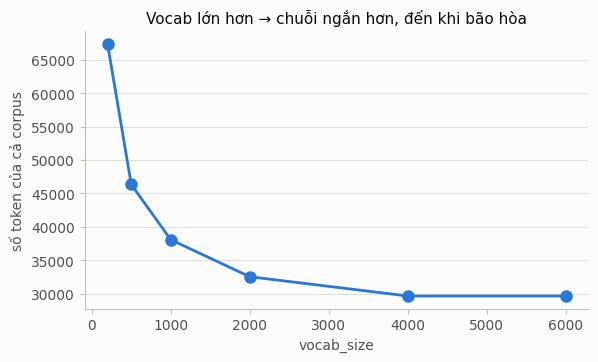

In [12]:
sizes = [200, 500, 1000, 2000, 4000, 6000]
token_counts = []
with tempfile.TemporaryDirectory() as tmp:
    for v in sizes:
        tok_v = VietTokenizer.train(text, f"{tmp}/bpe{v}", vocab_size=v)
        token_counts.append(len(tok_v.encode(text)))
        print(f"vocab {v:5d}: {token_counts[-1]:6d} token | câu đầu: {tok_v.encode_as_pieces(lines[0])}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(sizes, token_counts, marker="o", markersize=8)
ax.set(xlabel="vocab_size", ylabel="số token của cả corpus", title="Vocab lớn hơn → chuỗi ngắn hơn, đến khi bão hòa")
ax.grid(axis="y")
plt.show()

Từ khoảng 4.000 trở đi đường cong nằm ngang: lúc đó **mọi âm tiết** của Truyện Kiều đã là một token, và vì
SentencePiece mặc định không ghép qua khoảng trắng nên không còn gì để ghép thêm. Với tiếng Việt, BPE gần như
"học lại" âm tiết, khác với tiếng Anh nơi một từ dài thường bị cắt thành nhiều mảnh. Vì thế ta chọn
`vocab_size = 4000`, và văn bản mô hình sinh ra luôn gồm các âm tiết viết đúng chính tả.

### 3.6. Cho BPE ghép qua khoảng trắng

Nếu đặt `split_by_whitespace=False`, BPE được phép ghép cả các âm tiết đứng cạnh nhau và sẽ tự "phát hiện"
các từ ghép, tên riêng và cụm từ hay gặp:

In [13]:
with tempfile.TemporaryDirectory() as tmp:
    tok_ws = VietTokenizer.train(text, f"{tmp}/bpe_ws", vocab_size=4000, split_by_whitespace=False)
    multi = [tok_ws.id_to_piece(i) for i in range(tok_ws.vocab_size) if tok_ws.id_to_piece(i).count("▁") >= 2]
    print(f"{len(multi)} token gồm từ 2 âm tiết trở lên, ví dụ:\n{multi[:60]}\n")
    print("Câu đầu:", tok_ws.encode_as_pieces(lines[0]))

1272 token gồm từ 2 âm tiết trở lên, ví dụ:
['▁Nàng▁rằng', '▁Tiểu▁th', '▁nàng▁mới', '▁Tiểu▁thư', '▁một▁v', '▁Giác▁Duyên', '▁Một▁lời', '▁một▁lời', '▁Những▁là', '▁Lâm▁Tr', '▁Bây▁giờ', '▁làm▁sao', '▁thế▁này', '▁một▁mình', '▁thì▁cũng', '▁thì▁thôi', '▁Cùng▁nhau', '▁đã▁d', '▁đâu▁mà', '▁Làm▁cho', '▁Một▁nhà', '▁bao▁giờ', '▁bây▁giờ', '▁bấy▁lâu', '▁một▁ngày', '▁xa▁gần', '▁nàng▁đã', '▁đã▁thấy', '▁vội▁vàng', '▁Sinh▁rằng', '▁Tú▁Bà', '▁bước▁ra', '▁làm▁chi', '▁một▁hai', '▁một▁vài', '▁Một▁mình', '▁Nghe▁lời', '▁hồng▁nhan', '▁đâu▁đã', '▁Làm▁chi', '▁cũng▁là', '▁thế▁nào', '▁xưa▁nay', '▁đến▁nơi', '▁rụng▁rời', '▁Thưa▁rằng', '▁chiêm▁bao', '▁một▁người', '▁phong▁trần', '▁thong▁dong', '▁Đoạn▁trường', '▁là▁đ', '▁tan▁t', '▁về▁sau', '▁Lâm▁Tri', '▁biết▁là', '▁bời▁bời', '▁hôm▁nay', '▁lại▁gặp', '▁một▁nhà']

Câu đầu: ['▁Trăm▁năm', '▁trong', '▁cõi', '▁người▁ta', ',']


Ta thấy tên riêng (`▁Tú▁Bà`, `▁Giác▁Duyên`), từ ghép (`▁hồng▁nhan`, `▁phong▁trần`, `▁chiêm▁bao`) nhưng cũng
có cụm không phải từ (`▁nàng▁mới`) hay mảnh cụt (`▁Tiểu▁th`). BPE chỉ đếm tần suất, nó không hiểu nghĩa.

Repo này vẫn giữ `split_by_whitespace=True` vì: token ≈ âm tiết nên dễ đọc khi vẽ attention, khớp với vector
fastText mức âm tiết ở notebook 02, và mô hình chỉ có thể sinh ra các âm tiết có thật.

## Tóm tắt

* Token là đơn vị mô hình nhìn thấy; tokenizer biến văn bản ↔ danh sách token id.
* Luôn **chuẩn hóa NFC** trước khi làm gì khác với văn bản tiếng Việt.
* Ký tự: vocab nhỏ, chuỗi dài. Âm tiết: chuỗi ngắn, nhưng gặp từ lạ là bó tay. BPE: dung hòa cả hai.
* Tokenizer BPE 4.000 token đã được lưu ở `data/truyen_kieu_bpe4000.model`; các notebook sau nạp lại bằng `get_tokenizer()`.

**Tiếp theo:** notebook 02 biến mỗi token id thành một vector (embedding).

---

## Bài tập

Đáp án: `solutions/01_tokenization.md`

**Bài 1.** Văn bản `mixed` dưới đây trộn dòng NFC và dòng NFD. Đếm số âm tiết khác nhau (dùng
`re.findall(r"\w+", ...)` rồi đưa vào `set`) khi **không** chuẩn hóa và khi **có** chuẩn hóa bằng
`normalize_text`. Vì sao hai con số khác nhau?

In [14]:
mixed = "\n".join(l if i % 2 == 0 else unicodedata.normalize("NFD", l) for i, l in enumerate(lines[:200]))

# TODO: thay None bằng code của bạn
n_without_nfc = None
n_with_nfc = None

print("Không chuẩn hóa:", n_without_nfc, "| Có chuẩn hóa:", n_with_nfc)

Không chuẩn hóa: None | Có chuẩn hóa: None


**Bài 2.** Tokenizer BPE tách "buýt" thành mảnh thay vì `<unk>`.
(a) Vì sao với văn bản tiếng Việt thông thường, tokenizer của ta hầu như không cần `<unk>`?
(b) Khi nào nó vẫn sinh ra `<unk>`? Tìm một câu như vậy và kiểm tra bằng code.

In [15]:
# TODO: thay câu dưới đây bằng một câu khiến tokenizer sinh ra <unk>
example = "Trăm năm trong cõi người ta"
print(tokenizer.encode_as_pieces(example))
print("Có <unk>?", tokenizer.unk_id in tokenizer.encode(example))

['▁Trăm', '▁năm', '▁trong', '▁cõi', '▁người', '▁ta']
Có <unk>? False


**Bài 3.** SentencePiece còn có thuật toán `unigram`. Huấn luyện hai tokenizer cùng `vocab_size=1000`, một
`model_type="bpe"` và một `model_type="unigram"`, rồi so sánh cách tách 3 câu đầu và tổng số token của cả
corpus. Tokenizer nào cho chuỗi ngắn hơn?

In [16]:
with tempfile.TemporaryDirectory() as tmp:
    # TODO: huấn luyện hai tokenizer bằng VietTokenizer.train(text, f"{tmp}/...", vocab_size=1000, model_type=...)
    pass